In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA = PROJECT_ROOT / "data" / "processed"

print("Project root:", PROJECT_ROOT)

Project root: c:\Users\chivi\OneDrive\Documentos\GitHub\TFG_software


In [2]:
# Load municipal household disposable income
rfdb_raw = pd.read_csv(
    RAW_DATA / "rfdb_municipalities.csv",
    sep=";",
    encoding="utf-8-sig"
)

# Convert numeric values, including decimal commas in the index indicator
rfdb_raw["valor"] = pd.to_numeric(
    rfdb_raw["valor"].astype(str).str.replace(",", ".", regex=False),
    errors="coerce"
)

print("RFDB dataset shape:", rfdb_raw.shape)
print("Available years:", sorted(rfdb_raw["año"].unique()))
display(rfdb_raw.head())

RFDB dataset shape: (19782, 6)
Available years: [np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]


,año,municipio,concepto,indicador,estado,valor
0,2010,Abrera,renta disponible bruta de los hogares,valor (miles €),NaN,197787.0
1,2010,Abrera,renta disponible bruta de los hogares,por habitante (€),NaN,17241.0
2,2010,Abrera,renta disponible bruta de los hogares,por habitante (índice Cataluña=100),NaN,101.8
3,2010,Agramunt,renta disponible bruta de los hogares,valor (miles €),NaN,78123.0
4,2010,Agramunt,renta disponible bruta de los hogares,por habitante (€),NaN,13956.0


In [3]:
rfdb_2023 = rfdb_raw.loc[
    (rfdb_raw["año"] == 2023)
    & (rfdb_raw["indicador"] == "por habitante (€)")
    & (rfdb_raw["concepto"] == "renta disponible bruta de los hogares"),
    ["municipio", "valor", "estado"]
].copy()

rfdb_2023 = rfdb_2023.rename(
    columns={"valor": "rfdb_per_capita_eur"}
)

assert not rfdb_2023["municipio"].duplicated().any()

print("Municipalities with RFDB data:", len(rfdb_2023))
display(
    rfdb_2023.sort_values(
        "rfdb_per_capita_eur", ascending=False
    ).head(10)
)

Municipalities with RFDB data: 471


,municipio,rfdb_per_capita_eur,estado
18406,Alella,35425.0,p
19003,Matadepera,34766.0,p
19408,Sant Just Desvern,33256.0,p
18622,Cabrils,31280.0,p
19336,Sant Cugat del Vallès,30434.0,p
19597,Tiana,28136.0,p
19588,Teià,28108.0,p
18619,Cabrera de Mar,27805.0,p
18859,Fornells de la Selva,27805.0,p
18538,Begues,27588.0,p


In [4]:
seasonal_raw = pd.read_csv(
    RAW_DATA / "seasonal_population_quarterly.csv",
    skiprows=7,
    encoding="utf-8-sig",
    dtype={"Codi": str},
    na_values=["..", "...", ""]
)

print("Seasonal dataset shape:", seasonal_raw.shape)
print("Columns:")
print(seasonal_raw.columns.tolist())

display(seasonal_raw.head())

Seasonal dataset shape: (485, 9)
Columns:
['Codi', 'Nom', 'Població estacional ETCA. T1', 'Població estacional ETCA. T2', 'Població estacional ETCA. T3', 'Població estacional ETCA. T4', 'Població estacional ETCA. Total', 'Població resident', 'Població ETCA']


,Codi,Nom,Població estacional ETCA. T1,Població estacional ETCA. T2,Població estacional ETCA. T3,Població estacional ETCA. T4,Població estacional ETCA. Total,Població resident,Població ETCA
0,080018,Abrera,83.0,-40.0,-603.0,39.0,-130.0,12981,12851.0
1,250030,Agramunt,-281.0,-369.0,-554.0,-264.0,-366.0,5592,5226.0
2,080142,Aiguafreda,-192.0,-235.0,-283.0,-200.0,-227.0,2582,2355.0
3,430017,Aiguamúrcia,4.0,32.0,129.0,31.0,49.0,965,1014.0
4,170025,Aiguaviva,279.0,291.0,169.0,293.0,258.0,800,1058.0


In [5]:
seasonal = seasonal_raw.rename(columns={
    "Nom": "municipio",
    "Població estacional ETCA. T1": "seasonal_t1",
    "Població estacional ETCA. T2": "seasonal_t2",
    "Població estacional ETCA. T3": "seasonal_t3",
    "Població estacional ETCA. T4": "seasonal_t4",
    "Població estacional ETCA. Total": "seasonal_total",
    "Població resident": "resident_population_2024",
    "Població ETCA": "population_etca_2024"
})

seasonal_columns = [
    "seasonal_t1",
    "seasonal_t2",
    "seasonal_t3",
    "seasonal_t4",
    "seasonal_total",
    "resident_population_2024",
    "population_etca_2024"
]

for column in seasonal_columns:
    seasonal[column] = pd.to_numeric(
        seasonal[column], errors="coerce"
    )

seasonal = seasonal[
    ["municipio"] + seasonal_columns
].copy()

# Harmonise known municipal naming differences
seasonal["municipio"] = seasonal["municipio"].replace({
    "Palamós i Sant Joan": "Palamós"
})

assert not seasonal["municipio"].duplicated().any()

display(seasonal.head())

,municipio,seasonal_t1,seasonal_t2,seasonal_t3,seasonal_t4,seasonal_total,resident_population_2024,population_etca_2024
0,Abrera,83.0,-40.0,-603.0,39.0,-130.0,12981,12851.0
1,Agramunt,-281.0,-369.0,-554.0,-264.0,-366.0,5592,5226.0
2,Aiguafreda,-192.0,-235.0,-283.0,-200.0,-227.0,2582,2355.0
3,Aiguamúrcia,4.0,32.0,129.0,31.0,49.0,965,1014.0
4,Aiguaviva,279.0,291.0,169.0,293.0,258.0,800,1058.0


In [6]:
demographic = pd.read_csv(
    PROCESSED_DATA / "demographic_municipality_stats_2025.csv",
    encoding="utf-8-sig"
)

# Merge the three data sources
analysis_df = (
    demographic
    .merge(
        rfdb_2023[["municipio", "rfdb_per_capita_eur"]],
        on="municipio",
        how="left",
        validate="one_to_one"
    )
    .merge(
        seasonal,
        on="municipio",
        how="left",
        validate="one_to_one"
    )
)

print("Integrated dataset shape:", analysis_df.shape)
print("Municipalities:", analysis_df["municipio"].nunique())

display(analysis_df.head())

Integrated dataset shape: (948, 12)
Municipalities: 948


,municipio,population_total,population_60_plus,pct_60_plus,rfdb_per_capita_eur,seasonal_t1,seasonal_t2,seasonal_t3,seasonal_t4,seasonal_total,resident_population_2024,population_etca_2024
0,Catalunya,8124126,2106500,25.928943,20789.0,NaN,NaN,NaN,NaN,NaN,8012231.0,NaN
1,Barcelona,1713247,460936,26.904235,25898.0,135469.0,138045.0,-28400.0,144003.0,96891.0,1686208.0,1783099.0
2,"Hospitalet de Llobregat, l'",292161,70588,24.160651,17591.0,-14554.0,-18757.0,-31477.0,-15650.0,-20110.0,282299.0,262189.0
3,Badalona,230642,59881,25.962747,19114.0,-14479.0,-18044.0,-23461.0,-15059.0,-17760.0,226219.0,208459.0
4,Sabadell,224589,57424,25.568483,20303.0,-11620.0,-15061.0,-22768.0,-11933.0,-15388.0,221564.0,206176.0


In [7]:
coverage = pd.DataFrame({
    "indicator": [
        "RFDB per capita",
        "Seasonal population"
    ],
    "municipalities_available": [
        analysis_df["rfdb_per_capita_eur"].notna().sum(),
        analysis_df["seasonal_total"].notna().sum()
    ]
})

coverage["coverage_pct"] = (
    100 * coverage["municipalities_available"]
    / len(analysis_df)
)

display(coverage.round(2))

,indicator,municipalities_available,coverage_pct
0,RFDB per capita,471,49.68
1,Seasonal population,484,51.05


In [8]:
costa_brava_municipalities = [
    "Blanes",
    "Lloret de Mar",
    "Tossa de Mar",
    "Santa Cristina d'Aro",
    "Sant Feliu de Guíxols",
    "Castell d'Aro, Platja d'Aro i s'Agaró",
    "Calonge i Sant Antoni",
    "Palamós",
    "Palafrugell",
    "Mont-ras",
    "Begur",
    "Pals",
    "Torroella de Montgrí",
    "Escala, l'",
    "Sant Pere Pescador",
    "Castelló d'Empúries",
    "Roses",
    "Cadaqués",
    "Port de la Selva, el",
    "Llançà",
    "Colera",
    "Portbou",
]
costa_brava_stats = analysis_df.loc[
    analysis_df["municipio"].isin(costa_brava_municipalities)
].copy()

costa_brava_stats = costa_brava_stats.sort_values(
    "population_60_plus",
    ascending=False
)

display(
    costa_brava_stats[
        [
            "municipio",
            "population_total",
            "population_60_plus",
            "pct_60_plus",
            "rfdb_per_capita_eur",
            "seasonal_total",
            "resident_population_2024",
            "population_etca_2024"
        ]
    ].round(2)
)

,municipio,population_total,population_60_plus,pct_60_plus,rfdb_per_capita_eur,seasonal_total,resident_population_2024,population_etca_2024
27,Blanes,42446,11616,27.37,16740.0,5823.0,41935.0,47758.0
34,Lloret de Mar,41944,9863,23.51,14009.0,18545.0,42134.0,60679.0
54,Sant Feliu de Guíxols,23060,6455,27.99,16547.0,2536.0,22934.0,25470.0
55,Palafrugell,24556,6314,25.71,16599.0,6494.0,24245.0,30739.0
65,Palamós,18921,5498,29.06,17928.0,4395.0,18619.0,23014.0
68,Roses,20175,5277,26.16,14578.0,9196.0,20255.0,29451.0
98,Calonge i Sant Antoni,12268,3650,29.75,17110.0,6898.0,12203.0,19101.0
101,"Castell d'Aro, Platja d'Aro i s'Agaró",12889,3484,27.03,15274.0,9240.0,12773.0,22013.0
107,Torroella de Montgrí,12507,3366,26.91,16376.0,8624.0,12421.0,21045.0
109,"Escala, l'",10641,3292,30.94,16283.0,6618.0,10630.0,17248.0


In [9]:
# Investigate missing municipality matches

demographic_names = set(demographic["municipio"])
rfdb_names = set(rfdb_2023["municipio"])
seasonal_names = set(seasonal["municipio"])

print("Municipalities in demographic dataset:", len(demographic_names))
print("Municipalities in RFDB dataset:", len(rfdb_names))
print("Municipalities in seasonal dataset:", len(seasonal_names))

print("\nMunicipalities missing RFDB data:")
print(sorted(demographic_names - rfdb_names)[:30])

print("\nMunicipalities missing seasonal data:")
print(sorted(demographic_names - seasonal_names)[:30])

Municipalities in demographic dataset: 948
Municipalities in RFDB dataset: 471
Municipalities in seasonal dataset: 485

Municipalities missing RFDB data:
['Abella de la Conca', 'Aguilar de Segarra', 'Agullana', 'Aiguamúrcia', 'Aiguaviva', 'Alamús, els', "Albagés, l'", 'Albanyà', "Albi, l'", "Albiol, l'", 'Albons', 'Alcanó', 'Aldover', "Aleixar, l'", 'Alfara de Carles', 'Alfés', 'Algerri', 'Alins', 'Alió', 'Almatret', 'Alpens', 'Alt Àneu', 'Alàs i Cerc', 'Alòs de Balaguer', 'Arbolí', 'Argelaguer', "Argentera, l'", 'Argençola', 'Arnes', 'Arres']

Municipalities missing seasonal data:
['Abella de la Conca', 'Aguilar de Segarra', 'Agullana', 'Alamús, els', "Albagés, l'", 'Albanyà', "Albi, l'", "Albiol, l'", 'Albons', 'Alcanó', 'Aldover', "Aleixar, l'", 'Alfara de Carles', 'Alfés', 'Algerri', 'Alins', 'Alió', 'Almatret', 'Alpens', 'Alt Àneu', 'Alàs i Cerc', 'Alòs de Balaguer', 'Arbolí', 'Argelaguer', "Argentera, l'", 'Argençola', 'Arnes', 'Arres', 'Arsèguel', 'Aspa']


In [10]:
# Inspect the highest and lowest RFDB per-capita values

display(
    rfdb_2023.sort_values(
        "rfdb_per_capita_eur",
        ascending=False
    ).head(20)
)

display(
    rfdb_2023["rfdb_per_capita_eur"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

,municipio,rfdb_per_capita_eur,estado
18406,Alella,35425.0,p
19003,Matadepera,34766.0,p
19408,Sant Just Desvern,33256.0,p
18622,Cabrils,31280.0,p
19336,Sant Cugat del Vallès,30434.0,p
19597,Tiana,28136.0,p
19588,Teià,28108.0,p
18619,Cabrera de Mar,27805.0,p
18859,Fornells de la Selva,27805.0,p
18538,Begues,27588.0,p


count      471.000000
mean     19229.791932
std       3002.630199
min      13633.000000
1%       14510.400000
5%       15282.500000
25%      17175.500000
50%      19012.000000
75%      20619.500000
95%      24506.000000
99%      28825.400000
max      35425.000000
Name: rfdb_per_capita_eur, dtype: float64

In [11]:
display(
    rfdb_raw.loc[
        rfdb_raw["municipio"].str.contains(
            "Begur", case=False, na=False
        )
        & (rfdb_raw["año"] == 2023),
        :
    ]
)

,año,municipio,concepto,indicador,estado,valor
18540,2023,Begur,renta disponible bruta de los hogares,valor (miles €),p,94116.0
18541,2023,Begur,renta disponible bruta de los hogares,por habitante (€),p,22271.0
18542,2023,Begur,renta disponible bruta de los hogares,por habitante (índice Cataluña=100),p,107.1


In [12]:
seasonal["seasonal_difference_check"] = (
    seasonal["population_etca_2024"]
    - seasonal["resident_population_2024"]
)

seasonal["seasonal_check_difference"] = (
    seasonal["seasonal_difference_check"]
    - seasonal["seasonal_total"]
)

display(
    seasonal[
        [
            "municipio",
            "seasonal_total",
            "resident_population_2024",
            "population_etca_2024",
            "seasonal_check_difference"
        ]
    ].head(15)
)

print(
    "Municipalities with non-zero differences:",
    (seasonal["seasonal_check_difference"].abs() > 1).sum()
)

,municipio,seasonal_total,resident_population_2024,population_etca_2024,seasonal_check_difference
0,Abrera,-130.0,12981,12851.0,0.0
1,Agramunt,-366.0,5592,5226.0,0.0
2,Aiguafreda,-227.0,2582,2355.0,0.0
3,Aiguamúrcia,49.0,965,1014.0,0.0
4,Aiguaviva,258.0,800,1058.0,0.0
5,Aitona,-160.0,2575,2415.0,0.0
6,Albatàrrec,-298.0,2247,1949.0,0.0
7,Albesa,-148.0,1571,1423.0,0.0
8,Albinyana,-246.0,2678,2432.0,0.0
9,Alcanar,164.0,9871,10035.0,0.0


Municipalities with non-zero differences: 0


In [13]:
# Check data coverage for the Costa Brava sample

target_names = set(costa_brava_municipalities)

coverage_coast = analysis_df.loc[
    analysis_df["municipio"].isin(target_names),
    [
        "municipio",
        "population_total",
        "population_60_plus",
        "pct_60_plus",
        "rfdb_per_capita_eur",
        "seasonal_total",
    ],
].copy()

coverage_coast["has_rfdb"] = (
    coverage_coast["rfdb_per_capita_eur"].notna()
)

coverage_coast["has_seasonal_data"] = (
    coverage_coast["seasonal_total"].notna()
)

display(
    coverage_coast.sort_values(
        "population_60_plus",
        ascending=False
    )
)

print(
    "Municipalities with both sources:",
    (
        coverage_coast["has_rfdb"]
        & coverage_coast["has_seasonal_data"]
    ).sum(),
    "of",
    len(coverage_coast),
)

,municipio,population_total,population_60_plus,pct_60_plus,rfdb_per_capita_eur,seasonal_total,has_rfdb,has_seasonal_data
27,Blanes,42446,11616,27.366536,16740.0,5823.0,True,True
34,Lloret de Mar,41944,9863,23.514686,14009.0,18545.0,True,True
54,Sant Feliu de Guíxols,23060,6455,27.992194,16547.0,2536.0,True,True
55,Palafrugell,24556,6314,25.712657,16599.0,6494.0,True,True
65,Palamós,18921,5498,29.057661,17928.0,4395.0,True,True
68,Roses,20175,5277,26.156134,14578.0,9196.0,True,True
98,Calonge i Sant Antoni,12268,3650,29.752201,17110.0,6898.0,True,True
101,"Castell d'Aro, Platja d'Aro i s'Agaró",12889,3484,27.030801,15274.0,9240.0,True,True
107,Torroella de Montgrí,12507,3366,26.912929,16376.0,8624.0,True,True
109,"Escala, l'",10641,3292,30.936942,16283.0,6618.0,True,True


Municipalities with both sources: 21 of 22


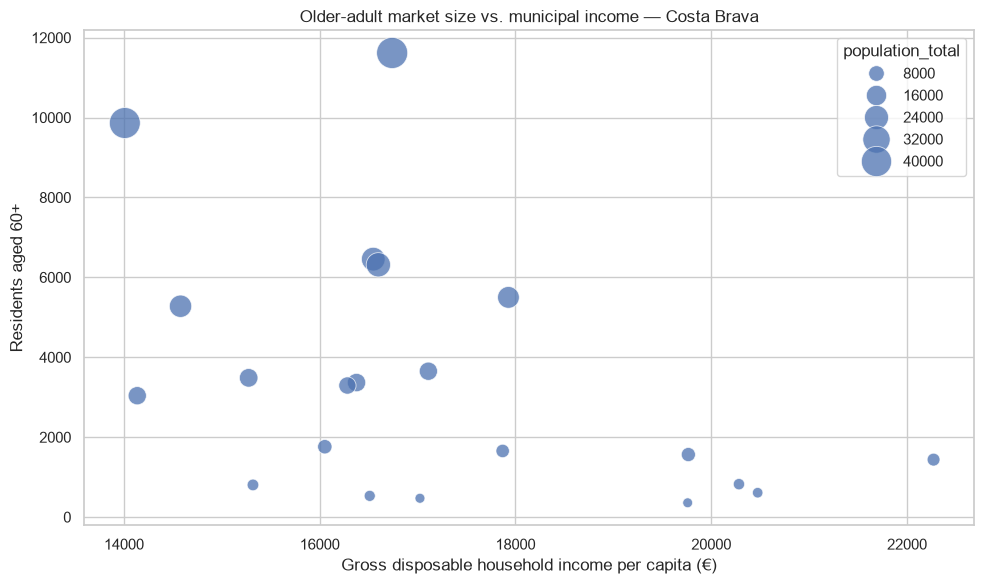

In [14]:
# Market size vs. municipal disposable income

plot_df = costa_brava_stats.dropna(
    subset=["population_60_plus", "rfdb_per_capita_eur"]
).copy()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_df,
    x="rfdb_per_capita_eur",
    y="population_60_plus",
    size="population_total",
    sizes=(50, 500),
    alpha=0.75
)

plt.title("Older-adult market size vs. municipal income — Costa Brava")
plt.xlabel("Gross disposable household income per capita (€)")
plt.ylabel("Residents aged 60+")
plt.tight_layout()
plt.show()

In [15]:
display(
    plot_df[
        [
            "municipio",
            "population_60_plus",
            "pct_60_plus",
            "rfdb_per_capita_eur",
            "seasonal_total"
        ]
    ]
    .sort_values("population_60_plus", ascending=False)
    .round(2)
)

,municipio,population_60_plus,pct_60_plus,rfdb_per_capita_eur,seasonal_total
27,Blanes,11616,27.37,16740.0,5823.0
34,Lloret de Mar,9863,23.51,14009.0,18545.0
54,Sant Feliu de Guíxols,6455,27.99,16547.0,2536.0
55,Palafrugell,6314,25.71,16599.0,6494.0
65,Palamós,5498,29.06,17928.0,4395.0
68,Roses,5277,26.16,14578.0,9196.0
98,Calonge i Sant Antoni,3650,29.75,17110.0,6898.0
101,"Castell d'Aro, Platja d'Aro i s'Agaró",3484,27.03,15274.0,9240.0
107,Torroella de Montgrí,3366,26.91,16376.0,8624.0
109,"Escala, l'",3292,30.94,16283.0,6618.0


In [ ]:
# Seasonal population relative to resident population
costa_brava_stats["seasonal_intensity_pct"] = (
    100 * costa_brava_stats["seasonal_total"]
    / costa_brava_stats["resident_population_2024"]
)

seasonal_ranking = costa_brava_stats[
    [
        "municipio",
        "population_60_plus",
        "rfdb_per_capita_eur",
        "seasonal_total",
        "seasonal_intensity_pct"
    ]
].sort_values(
    "seasonal_intensity_pct",
    ascending=False
)

display(seasonal_ranking.round(2))

In [19]:
# Seasonal population relative to resident population
costa_brava_stats["seasonal_intensity_pct"] = (
    100 * costa_brava_stats["seasonal_total"]
    / costa_brava_stats["resident_population_2024"]
)

seasonal_ranking = costa_brava_stats[
    [
        "municipio",
        "population_60_plus",
        "rfdb_per_capita_eur",
        "seasonal_total",
        "seasonal_intensity_pct"
    ]
].sort_values(
    "seasonal_intensity_pct",
    ascending=False
)

display(seasonal_ranking.round(2))

,municipio,population_60_plus,rfdb_per_capita_eur,seasonal_total,seasonal_intensity_pct
432,"Port de la Selva, el",357,19759.0,1971.0,186.29
285,Pals,823,20283.0,4250.0,164.54
365,Sant Pere Pescador,530,16511.0,2932.0,132.85
180,Tossa de Mar,1760,16052.0,6819.0,109.26
204,Begur,1437,22271.0,3725.0,88.12
288,Cadaqués,804,15318.0,2478.0,85.63
101,"Castell d'Aro, Platja d'Aro i s'Agaró",3484,15274.0,9240.0,72.34
107,Torroella de Montgrí,3366,16376.0,8624.0,69.43
109,"Escala, l'",3292,16283.0,6618.0,62.26
188,Llançà,1654,17869.0,2930.0,58.04


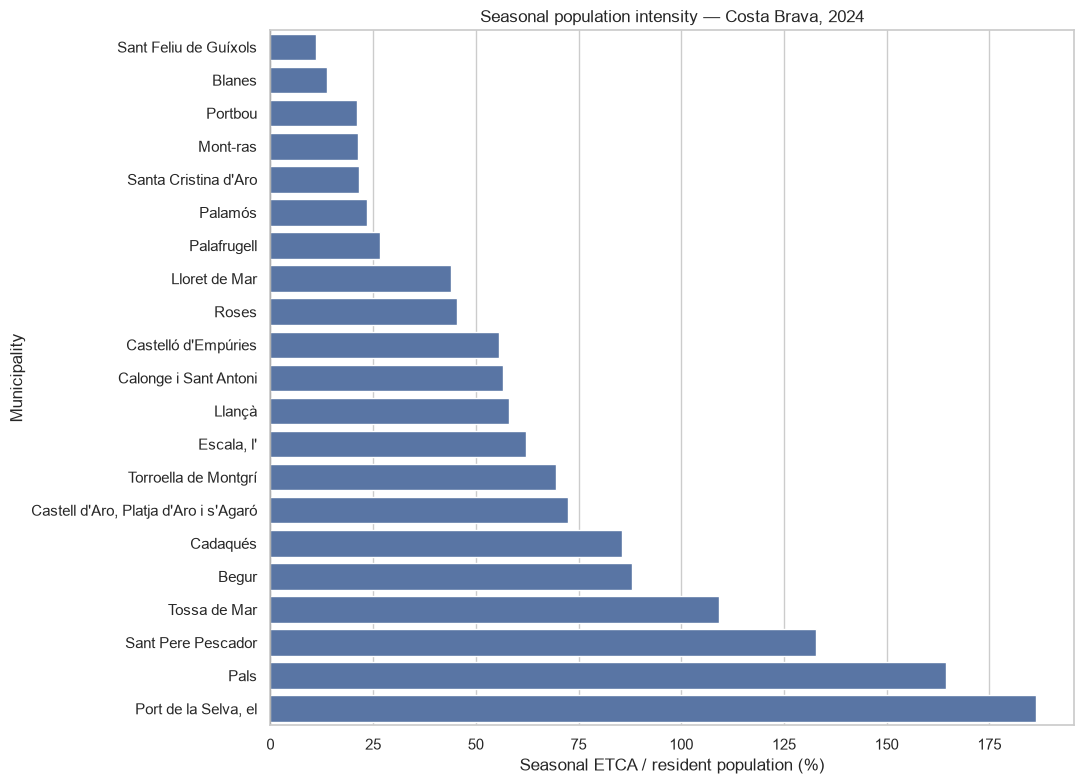

In [20]:
plot_seasonal = seasonal_ranking.dropna(
    subset=["seasonal_intensity_pct"]
).sort_values("seasonal_intensity_pct")

plt.figure(figsize=(11, 8))

sns.barplot(
    data=plot_seasonal,
    x="seasonal_intensity_pct",
    y="municipio"
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Seasonal population intensity — Costa Brava, 2024")
plt.xlabel("Seasonal ETCA / resident population (%)")
plt.ylabel("Municipality")
plt.tight_layout()
plt.show()

In [24]:
from sklearn.preprocessing import MinMaxScaler

features = [
    "population_60_plus",
    "pct_60_plus",
    "rfdb_per_capita_eur",
    #"seasonal_intensity_pct"
]

weights = {
    "population_60_plus": 0.60,
    "pct_60_plus": 0.20,
    "rfdb_per_capita_eur": 0.20,
    #"seasonal_intensity_pct": 0.10
}

ranking_df = costa_brava_stats.dropna(
    subset=features
).copy()

scaler = MinMaxScaler()

normalized = scaler.fit_transform(
    ranking_df[features]
)

for i, feature in enumerate(features):
    ranking_df[f"{feature}_normalized"] = normalized[:, i]

ranking_df["opportunity_score"] = sum(
    ranking_df[f"{feature}_normalized"] * weight
    for feature, weight in weights.items()
)

ranking_df["opportunity_score"] *= 100

ranking_df = ranking_df.sort_values(
    "opportunity_score",
    ascending=False
)

display(
    ranking_df[
        ["municipio", "opportunity_score"] + features
    ].round(2)
)

,municipio,opportunity_score,population_60_plus,pct_60_plus,rfdb_per_capita_eur
27,Blanes,71.16,11616,27.37,16740.0
34,Lloret de Mar,51.01,9863,23.51,14009.0
54,Sant Feliu de Guíxols,43.88,6455,27.99,16547.0
65,Palamós,43.28,5498,29.06,17928.0
55,Palafrugell,40.76,6314,25.71,16599.0
204,Begur,37.03,1437,33.53,22271.0
98,Calonge i Sant Antoni,32.21,3650,29.75,17110.0
341,Mont-ras,31.01,609,36.04,20474.0
68,Roses,30.83,5277,26.16,14578.0
109,"Escala, l'",29.60,3292,30.94,16283.0


In [26]:

# Prepare seasonal analysis for Costa Brava municipalities

seasonal_df = costa_brava_stats.copy()

seasonal_df["seasonal_intensity_pct"] = (
    100
    * seasonal_df["seasonal_total"]
    / seasonal_df["resident_population_2024"]
)

display(
    seasonal_df[
        [
            "municipio",
            "seasonal_total",
            "resident_population_2024",
            "seasonal_intensity_pct"
        ]
    ].sort_values(
        "seasonal_intensity_pct",
        ascending=False
    ).round(2)
)


,municipio,seasonal_total,resident_population_2024,seasonal_intensity_pct
432,"Port de la Selva, el",1971.0,1058.0,186.29
285,Pals,4250.0,2583.0,164.54
365,Sant Pere Pescador,2932.0,2207.0,132.85
180,Tossa de Mar,6819.0,6241.0,109.26
204,Begur,3725.0,4227.0,88.12
288,Cadaqués,2478.0,2894.0,85.63
101,"Castell d'Aro, Platja d'Aro i s'Agaró",9240.0,12773.0,72.34
107,Torroella de Montgrí,8624.0,12421.0,69.43
109,"Escala, l'",6618.0,10630.0,62.26
188,Llançà,2930.0,5048.0,58.04


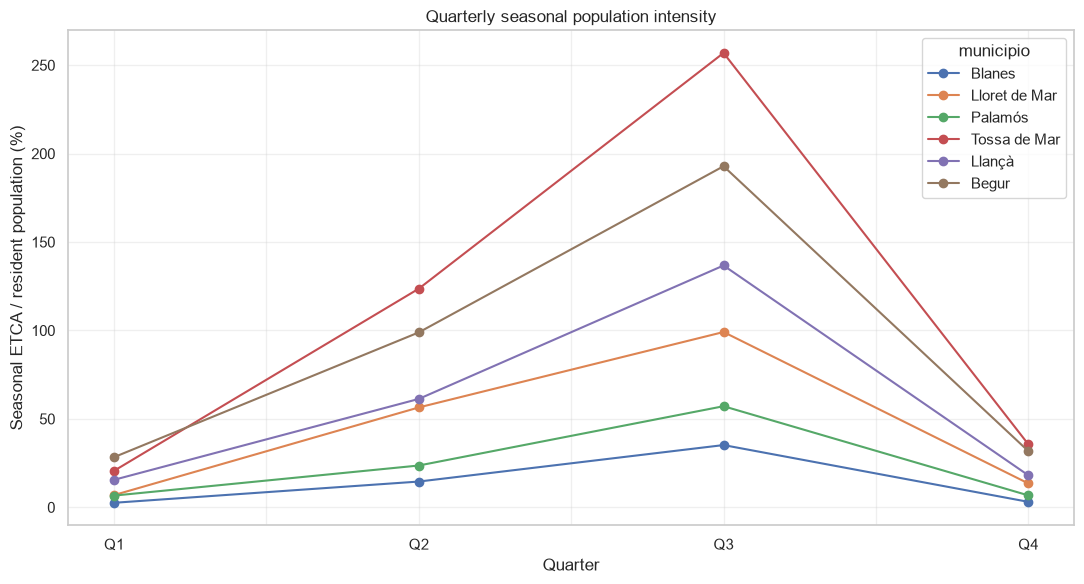

In [27]:
# Compare seasonal population patterns across municipalities

selected_municipalities = [
    "Blanes",
    "Lloret de Mar",
    "Begur",
    "Palamós",
    "Llançà",
    "Tossa de Mar"
]

quarter_cols = [
    "seasonal_t1",
    "seasonal_t2",
    "seasonal_t3",
    "seasonal_t4"
]

quarterly = seasonal_df.loc[
    seasonal_df["municipio"].isin(selected_municipalities),
    ["municipio", "resident_population_2024"] + quarter_cols
].copy()

# Express each quarter as a percentage of resident population
for col in quarter_cols:
    quarterly[col] = (
        100 * quarterly[col]
        / quarterly["resident_population_2024"]
    )

quarterly = quarterly.set_index("municipio")[quarter_cols]
quarterly.columns = ["Q1", "Q2", "Q3", "Q4"]

ax = quarterly.T.plot(figsize=(11, 6), marker="o")

ax.set_title("Quarterly seasonal population intensity")
ax.set_xlabel("Quarter")
ax.set_ylabel("Seasonal ETCA / resident population (%)")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
from pathlib import Path

PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)


# Renta y población estacional
rfdb_2023.to_csv(
    PROCESSED_DIR / "rfdb_municipality_2023.csv",
    index=False,
    encoding="utf-8-sig"
)

seasonal_df.to_csv(
    PROCESSED_DIR / "seasonal_population_municipality_2024.csv",
    index=False,
    encoding="utf-8-sig"
)

# Tablas integradas
analysis_df.to_csv(
    PROCESSED_DIR / "municipality_analysis_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

costa_brava_stats.to_csv(
    PROCESSED_DIR / "costa_brava_analysis_2025.csv",
    index=False,
    encoding="utf-8-sig"
)